# **Proposal Notebook**

Link to dataset: https://www.kaggle.com/datasets/annavictoria/speed-dating-experiment/data

This Kaggle dataset comes from a speed dating experiment conducted by Columbia Business School professors Ray Fisman and Sheena Iyengar for their paper titled "Gender Differences in Mate Selection: Evidence From a Speed Dating Experiment". The data was collected from participants in 4-minute speed dating events from 2002-2004. After the 4-minute dates, participants were asked to rate their date on various attributes, and if they'd like to see their date again. They also provided other personal information like demographics, dating habits, self-perception across key attributes, beliefs on what others find valuable in a mate, and lifestyle information. Each row is one first-date “round” between two people, so every pairing shows up twice, once from each person’s side. There are 551 participants across 21 waves (events).

Here is the dataset:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("data/speed_dating.csv")
df.head()

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


The key variables we will use are

Here are our research questions:
1. **Natalie - Are there systemic differences in how men and women evaluate their partners?** Many findings suggest men weigh attractiveness more heavily, whereas women weigh traits like ambition and intelligence. This dataset provides real in-person observations that may support or refute that claim.

2. **Aya - Are people who know what they want in a partner more successful at finding mutual matches?** Having a clear idea of what you want in a partner may help you find someone compatible, but it could also cause you to overlook people you might otherwise connect with. Exploring this relationship can help us understand whether having specific preferences leads to more mutual matches or whether finding a compatible partner depends on other factors as well.

3. **Delaney - Does a participant’s likelihood of saying "yes" or rating a date highly decline as the round number increases?** Understanding the patterns in which people rate others in the context of speed dating can help us see how effective dating games like this actually are. It can also be applied to life outside of a dating game, where people might be more or less likely to go out with someone depending on variables like time and how many people they’ve talked to.

# **Q1 (Natalie's Question): Are there systemic differences in how men and women evaluate their partners?**

The variables we will use to answer this question include *gender* (grouping variable), *iid, pid* (rater and partner ID), *attr, sinc, intel, fun, amb, shar* (ratings given on a scale from 1-10), and *dec* (decision to see their partner again or not).

## Data Wrangling

In [2]:
traits = ["attr", "sinc", "intel", "fun", "amb", "shar"]
cols = ["iid", "pid", "wave", "gender", "round", "order", "dec", "match"] + traits
new_df = df[cols].copy()
new_df

,iid,pid,wave,gender,round,order,dec,match,attr,sinc,intel,fun,amb,shar
0,1,11.0,1,0,10,4,1,0,6.0,9.0,7.0,7.0,6.0,5.0
1,1,12.0,1,0,10,3,1,0,7.0,8.0,7.0,8.0,5.0,6.0
2,1,13.0,1,0,10,10,1,1,5.0,8.0,9.0,8.0,5.0,7.0
3,1,14.0,1,0,10,5,1,1,7.0,6.0,8.0,7.0,6.0,8.0
4,1,15.0,1,0,10,7,1,1,5.0,6.0,7.0,7.0,6.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8373,552,526.0,21,1,22,5,0,0,3.0,5.0,5.0,5.0,NaN,NaN
8374,552,527.0,21,1,22,4,0,0,4.0,6.0,8.0,4.0,4.0,NaN
8375,552,528.0,21,1,22,10,0,0,4.0,7.0,8.0,8.0,8.0,NaN
8376,552,529.0,21,1,22,16,0,0,4.0,6.0,5.0,4.0,NaN,5.0


In [3]:
# Check range of ratings
new_df[traits].describe()

,attr,sinc,intel,fun,amb,shar
count,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000
mean,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559
std,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000
50%,6.000000,7.000000,7.000000,7.000000,7.000000,6.000000
75%,8.000000,8.000000,8.000000,8.000000,8.000000,7.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [4]:
# Check if any rows are missing data
new_df.isna().mean()
new_df.isna().sum()

iid          0
pid         10
wave         0
gender       0
round        0
order        0
dec          0
match        0
attr       202
sinc       277
intel      296
fun        350
amb        712
shar      1067
dtype: int64

In [5]:
# Keep only complete rows
d_clean = new_df.dropna(subset = traits + ['dec'])
print("Length of old data frame: ", len(new_df))
print("Length of new data frame: ", len(d_clean))
print("Number of each gender left:")
print(d_clean.groupby('gender')['iid'].nunique())

Length of old data frame:  8378
Length of new data frame:  7040
Number of each gender left:
gender
0    268
1    269
Name: iid, dtype: int64


Still to do:
- Average within-person, so someone who went on 20 dates doesn't count more than someone who went on 2.
- Standardize each person's rating, because some people may rate everyone highly and others rate everyone low.

## First Look Figure

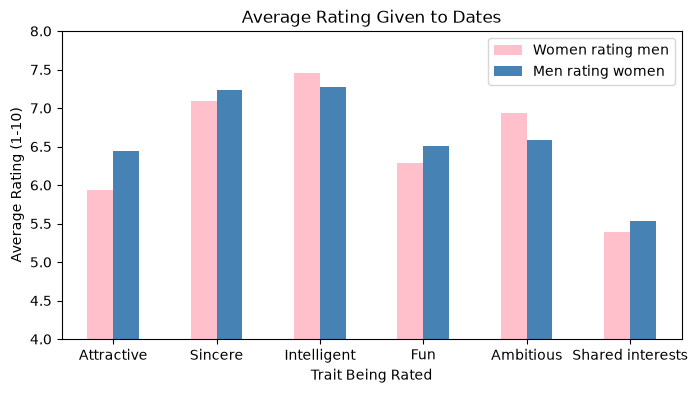

In [6]:
means = d_clean.groupby('gender')[traits].mean().T
means.columns = ['Women rating men', 'Men rating women']
means.index = ['Attractive', 'Sincere', 'Intelligent', 'Fun', 'Ambitious', 'Shared interests']

means.plot(kind='bar', color=['pink', 'steelblue'], figsize=(8, 4))
plt.ylim(4, 8)
plt.title('Average Rating Given to Dates')
plt.ylabel('Average Rating (1-10)')
plt.xlabel('Trait Being Rated')
plt.xticks(rotation=0)
plt.show()

## What I See

According to the graph, men tend to give higher attractiveness ratings (6.4 vs 5.9), which is the largest gap among the six traits. Women rate intelligence slightly higher than men (about 7.5 and 7.3) and ambition higher as well (about 6.9 vs 6.6). On the remaining traits, the two groups are very close, with men rating slightly higher. This suggests that men and women may not differ in how much they rate most qualities, but that attractiveness may be weighted differently. It's important to note that people who went on more dates count for more, as these averages are calculated across all dates. The graph also doesn't account for the fact that some people rate everyone high or low. 

## The Plan

My final figure will be a bar chart of regression coefficients, with one bar per trait + one for men and one for women. Each bar will show how much a one-point higher rating on the traits increases the chance that a person says "yes" to a date, so the chart shows which traits matter most to each gender. I'll predict the yes/no decision from the six trait ratings, fitting one model for men and a separate model for women, then compare the coefficients side by side. Then, I'm going to use a train/test split. I will split the data by person, fit each model (men's vs women's) on about 70% of that gender's participants, and check how often it correctly predicts the decisions of the remaining 30%. So I'll end up with 4 results: the men's model tested on the hidden men and women, and the women's model tested on the hidden men and women. If a model trained on women predicts men's decisions noticeably worse than it predicts other women's, that is evidence that men and women use different standards.

## Expected Outcomes

My hunch is that men and women do evaluate partners differently, especially on attractiveness. If I'm right, the coefficients for men and women will differ significantly (especially with attractiveness), and a model trained on one gender will predict the other gender's decisions less accurately than it predicts its own. If I'm wrong, the bars for men and women will be about the same height, and cross-gender prediction will work about as well as same-gender prediction. In that case, the gaps in my first-look figure would mean that men and women rate dates differently on average, but those ratings still turn into decisions in the same way. 

# **Q2 (Aya's Question): Are people who know what they want in a partner more successful at finding mutual matches?**

I am interested in whether people with more specific priorities for a romantic partner have different rates of mutual matches. The dataset does not directly ask people about deal-breakers or how willing they are to compromise, so I will use the concentration of their stated partner-attribute preferences as an exploratory proxy. This is not a direct measure of strict relational preferences, which is an important limitation.

## Variables
The preference variables are attr1_1 (attractiveness), sinc1_1 (sincerity), intel1_1 (intelligence), fun1_1 (fun), amb1_1 (ambition), and shar1_1 (shared interests). They record how important participants say these attributes are in a partner.
The outcome is match, which indicates whether both people chose each other. iid identifies each participant. Since participants went on multiple dates, I will calculate each person's proportion of dates that resulted in a mutual match.

## Preparation
First, I will inspect the variables and check for missing values. I will remove rows that are missing any of the six preference ratings, the participant ID, or the match outcome. I will divide each preference rating by the sum of the six ratings and add the squared proportions to make a preference-concentration score. Higher scores mean that the stated preferences are concentrated on fewer attributes; lower scores mean the importance is distributed more evenly. I will then group the data by participant and calculate each person's mutual-match rate.

This score is only a proxy for strictness. Someone can care strongly about several qualities without treating them as deal-breakers, and this dataset does not directly measure deal-breakers.

### Load and preview the data

In [7]:
import pandas as pd
df = pd.read_csv("data/speed_dating.csv")
df.shape

(8378, 195)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
preference_cols = [
    "attr1_1", "sinc1_1", "intel1_1",
    "fun1_1", "amb1_1", "shar1_1"
]

# variables used for this question
df[["iid", "match"] + preference_cols].head()

,iid,match,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1
0,1,0,15.0,20.0,20.0,15.0,15.0,15.0
1,1,0,15.0,20.0,20.0,15.0,15.0,15.0
2,1,1,15.0,20.0,20.0,15.0,15.0,15.0
3,1,1,15.0,20.0,20.0,15.0,15.0,15.0
4,1,1,15.0,20.0,20.0,15.0,15.0,15.0


### Check the data types and missing values

In [10]:
df[["iid", "match"] + preference_cols].info()

df[["iid", "match"] + preference_cols].isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   iid       8378 non-null   int64  
 1   match     8378 non-null   int64  
 2   attr1_1   8299 non-null   float64
 3   sinc1_1   8299 non-null   float64
 4   intel1_1  8299 non-null   float64
 5   fun1_1    8289 non-null   float64
 6   amb1_1    8279 non-null   float64
 7   shar1_1   8257 non-null   float64
dtypes: float64(6), int64(2)
memory usage: 523.8 KB


iid           0
match         0
attr1_1      79
sinc1_1      79
intel1_1     79
fun1_1       89
amb1_1       99
shar1_1     121
dtype: int64

### Prepare participant-level measures

In [11]:
# Keep rows with information needed 
analysis_df = df[["iid", "match"] + preference_cols].dropna(
    subset=["iid", "match"] + preference_cols
).copy()

# Remove rows where the six preference ratings sum to zero
preference_totals = analysis_df[preference_cols].sum(axis=1)
analysis_df = analysis_df[preference_totals > 0].copy()

# Convert the ratings to proportions and calculate preference concentration
preference_totals = analysis_df[preference_cols].sum(axis=1)
preference_shares = analysis_df[preference_cols].div(preference_totals, axis=0)
analysis_df["preference_concentration"] = (preference_shares ** 2).sum(axis=1)

# Summarize the repeated dates for each participant
participant_data = analysis_df.groupby("iid").agg(
    preference_concentration=("preference_concentration", "first"),
    match_rate=("match", "mean"),
    number_of_dates=("match", "size")
).reset_index()

print("Number of participants:", len(participant_data))
print("Average mutual-match rate:", participant_data["match_rate"].mean())
participant_data.head()

Number of participants: 541
Average mutual-match rate: 0.1687306823604129


,iid,preference_concentration,match_rate,number_of_dates
0,1,0.170,0.4,10
1,2,0.310,0.2,10
2,3,0.275,0.0,10
3,4,0.180,0.2,10
4,5,0.200,0.2,10


## First-look figure
I will use a scatterplot with a fitted line to compare each participant's preference-concentration score with their mutual-match rate. Each point represents one participant, rather than one date. The fitted line gives an initial view of the relationship, but it cannot show that preferences cause matching success.

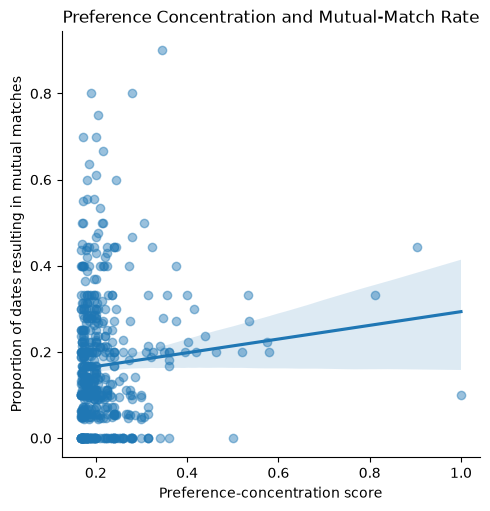

Correlation: 0.084


In [12]:
sns.lmplot(
    data=participant_data,
    x="preference_concentration",
    y="match_rate",
    scatter_kws={"alpha": 0.45}
)

plt.xlabel("Preference-concentration score")
plt.ylabel("Proportion of dates resulting in mutual matches")
plt.title("Preference Concentration and Mutual-Match Rate")
plt.show()

correlation = participant_data[
    ["preference_concentration", "match_rate"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

## What I see
The initial relationship is weakly positive. The correlation is about 0.08, which suggests that participants with more concentrated stated preferences may have slightly higher mutual-match rates. The relationship is small, and this score measures how concentrated preferences are rather than directly measuring strict deal-breakers, so this is only an initial observation.

## The plan
For the final analysis, I plan to make a figure that shows how mutual-match success varies across levels of preference concentration. I will use a regression model to test whether preference concentration is associated with mutual-match success, and I will consider whether initial attraction or other variables should be included. Since each participant has multiple interactions, I will account for repeated dates by the same participant where possible.
For the step beyond FDS I, I expect to evaluate the model on held-out data using a train/test split. I will choose a model and performance measure that fit the outcome and compare the predictions with a simple baseline. I will interpret the results as an association, not as proof that strict preferences cause mutual matches.

## Expected outcomes
**If my prediction is right**: I would expect a positive relationship between preference concentration and mutual-match rate. The fitted line would generally slope upward, and the regression coefficient for preference concentration would be positive.

**If my prediction is wrong**: I would expect little or no relationship, with a nearly flat trend and a regression coefficient close to zero. If the relationship is negative, that would suggest that participants with more concentrated preferences have lower mutual-match rates.

Either result would need to be interpreted carefully because preference concentration is not a direct measure of strictness, and factors such as attraction or compatibility could also influence mutual matches.

# **Q3 (Delaney's Question): Does a participant’s likelihood of saying "yes" or rating a date highly decline as the round number increases?**

## Section 1: Data & Questions

The key variables I will use in my question are `order`, `dec`, and `like`. `order` is what date it was (ex. the first date of the night or the second etc.). `dec` is the participant's decision about the person they went on a date with. 1 means 'yes', 0 means 'no'. `like` is overall how much the participant liked their partner.

## Section 2: Data Prep & Plan

In [13]:
# import data and view 10 random rows
import pandas as pd

df = pd.read_csv('data/speed_dating.csv')
df.sample(10)

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
2547,187,4.0,1,8,1,8,10,3,1.0,3,...,8.0,9.0,12.0,8.0,8.0,NaN,NaN,NaN,NaN,NaN
4785,317,10.0,1,19,2,12,14,1,1.0,2,...,7.0,3.0,7.0,8.0,6.0,7.0,6.0,7.0,8.0,6.0
4447,293,21.0,1,42,2,11,21,9,9.0,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6037,394,16.0,0,31,2,15,19,1,1.0,15,...,8.0,7.0,7.0,6.0,7.0,8.0,7.0,8.0,6.0,7.0
6670,440,1.0,1,2,2,17,11,6,3.0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2403,173,16.0,1,32,2,7,16,11,16.0,12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4000,272,21.0,0,41,2,11,21,6,6.0,8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1312,92,17.0,0,33,2,4,18,17,NaN,1,...,8.0,10.0,8.0,9.0,8.0,NaN,NaN,NaN,NaN,NaN
5383,360,20.0,0,38,2,14,18,1,1.0,12,...,7.0,9.0,8.0,7.0,8.0,8.0,9.0,7.0,7.0,8.0
5667,375,15.0,1,30,2,14,20,9,9.0,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# import packages
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

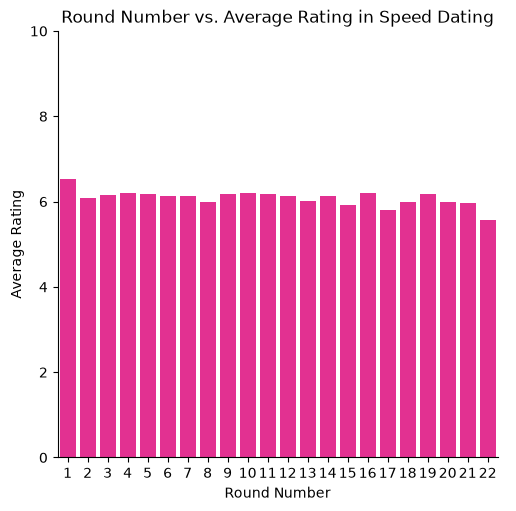

In [15]:
delaney_df = df[['order', 'dec', 'like']]
graph = sns.catplot(data = delaney_df,
                    x = 'order',
                    y = 'like',
                    kind = 'bar',
                    errorbar = None,
                    color = 'deeppink',
                   )

graph.set_axis_labels("Round Number", "Average Rating")
graph.set(title = "Round Number vs. Average Rating in Speed Dating")
graph.set(ylim = (0, 10));

**From this figure, we can see a consistent rating from round 5-12. In rounds 1-4 ratings start out around 6.5 and then decrease. From 5-12 the ratings remain pretty consistent at 6. Then from 13-22, ratings get more scattered, they go up and down, and ultimately end up around 5.75 for round 22.**

### First Look at the Figure

At first glance, it doesn't look like there's much of a pattern to be seen between what round number it is and what people rate their dates. There might be a slight negative relationship, but additional tests would need to be run in order to determine the statistical significance. We can visually see the average highest rating is consistently for the first round. This makes sense because people start off optimistic and in a good mood. 

### Our Plan

Right now this is a really simple visualization, but I'm looking forward to making it more in depth. I want to make the final graph interactive, and I want to incorporate more variables into it. By interactive, I hope to make it so when you click on a point you can see its x and y values. When adding more variables, I want to see how the ratings compare between people who said "yes" or "no" to their dates. The final product will be interactive and have a lot of information, however, it will still be simple enough to understand without a lot of context.

### Expected Outcomes

I could realistically understand if one of these two things happened. Firstly, it would make sense if people start to rate their dates higher towards the end of the night because they're getting more desperate. This would reflect itself as a positive relationship in the graph. However, I could also see people ranking their dates lower either because they met someone in an earlier round they really liked, or they're tired and are giving up. This would reflect itself as a negative relationship on the graph. There's also the possibility that we're wrong and there's no correlation. We could see this through a scattered graph or inconclusive statistical analysis. 